In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import os

In [ ]:
# Delete all PHI from csv before beginning
# Import CSV and convert to pandas dataframe

### Add new csv to the "content" folder and update the data_path name to the name of your csv ###
data_path = "/content/scans_9-14_9-21.csv"
data = pd.read_csv(data_path)
df = pd.DataFrame(data)

# df.head() will show you the first 5 lines of your csv
df.head()

,Case,Captured Date,Scans,Cells,Counters,Users,CR States,Scan Search Users,Last Viewed,Last Modified,Created,State
0,26-CQSKX_BLPMF,9/18/2026 9:57,2,0,0.0,"79614, Meta1, SRF99",Locked: 2,Meta1,RPK02,9/18/2026 16:24,9/5/2026 9:47,Captured
1,26-CZLNH_MDSDF,9/18/2026 0:49,6,0,0.0,"meta2, NAA93",Locked: 6,meta2,PTG04,9/18/2026 15:13,9/10/2026 13:01,Captured
2,26-DCDZY_PHLFD,9/17/2026 2:18,5,1,1.0,"MEB83, meta3, TKP99",Locked: 5,meta3,KND02,9/17/2026 11:30,9/11/2026 14:08,Captured
3,26-DCZWC_AMLFA,9/14/2026 7:56,4,0,0.0,"BXH97, Meta7",Locked: 4,Meta7,RPK02,9/15/2026 9:17,9/12/2026 8:06,Captured
4,26-DDCPF_BLPMF,9/14/2026 9:47,1,0,0.0,"77998, CLC97, Meta8",Locked: 1,Meta8,cjz99,9/15/2026 16:04,9/12/2026 8:52,Captured


In [ ]:
# Remove the case number and just keep the case type
df['Case Type'] = df['Case'].str.split('_').str[1]
# Rename Scan Search Users to Metafer
df['Metafer'] = df['Scan Search Users']

In [ ]:
# Check for missing values in the dataframe
df.isnull().sum()

,0
Case,0
Captured Date,0
Scans,0
Cells,0
Counters,5
Users,0
CR States,5
Scan Search Users,0
Last Viewed,51
Last Modified,0


In [ ]:
# Convert capture_date to datetime format
df['Captured Date'] = pd.to_datetime(df['Captured Date'])
# Create data and time columns
df['date'] = df['Captured Date'].dt.date
df['date'] = pd.to_datetime(df['date'])
df['time'] = df['Captured Date'].dt.time
# Create a new column for time bins (30-minute intervals)
df['time_bin'] = df['Captured Date'].dt.floor('30min').dt.time

In [ ]:
# Drop all of the columns from the csv that we don't want to keep
drop_list = ['Captured Date','Case','Cells','Counters','Users','CR States','Scan Search Users','Last Viewed','Last Modified','Created','State']
for col in drop_list:
  if col in df.columns:
    df = df.drop(col,axis=1)
df.head()

,Scans,Case Type,Metafer,date,time,time_bin
0,2,BLPMF,Meta1,2026-09-18,09:57:00,09:30:00
1,6,MDSDF,meta2,2026-09-18,00:49:00,00:30:00
2,5,PHLFD,meta3,2026-09-17,02:18:00,02:00:00
3,4,AMLFA,Meta7,2026-09-14,07:56:00,07:30:00
4,1,BLPMF,Meta8,2026-09-14,09:47:00,09:30:00


In [ ]:
# Extract the first Metafer number and standardize the label
original = df["Metafer"].astype("string")
metafer_num = df["Metafer"].astype("string").str.extract(
  r"(?i)meta(?:fer)?\s*([12378])(?!\d)",
  expand=False
)

df["Metafer"] = ("meta " + metafer_num).fillna(original)

# Drop invalid Metafers
valid_metafers = ['meta 1','meta 2','meta 3','meta 7','meta 8']

df = df[df["Metafer"].isin(valid_metafers)]

df['Metafer'].value_counts()

,count
Metafer,
meta 3,86
meta 1,84
meta 8,57
meta 7,53
meta 2,5


In [ ]:
# Save cleaned data

### Give a name to the cleaned dataframe you make ###
file_path = '/content/sep1-sep15_metafer_usage_cleaned.csv'
dir_path = os.path.dirname(file_path)
os.makedirs(dir_path, exist_ok=True)
df.to_csv(file_path, index=False)

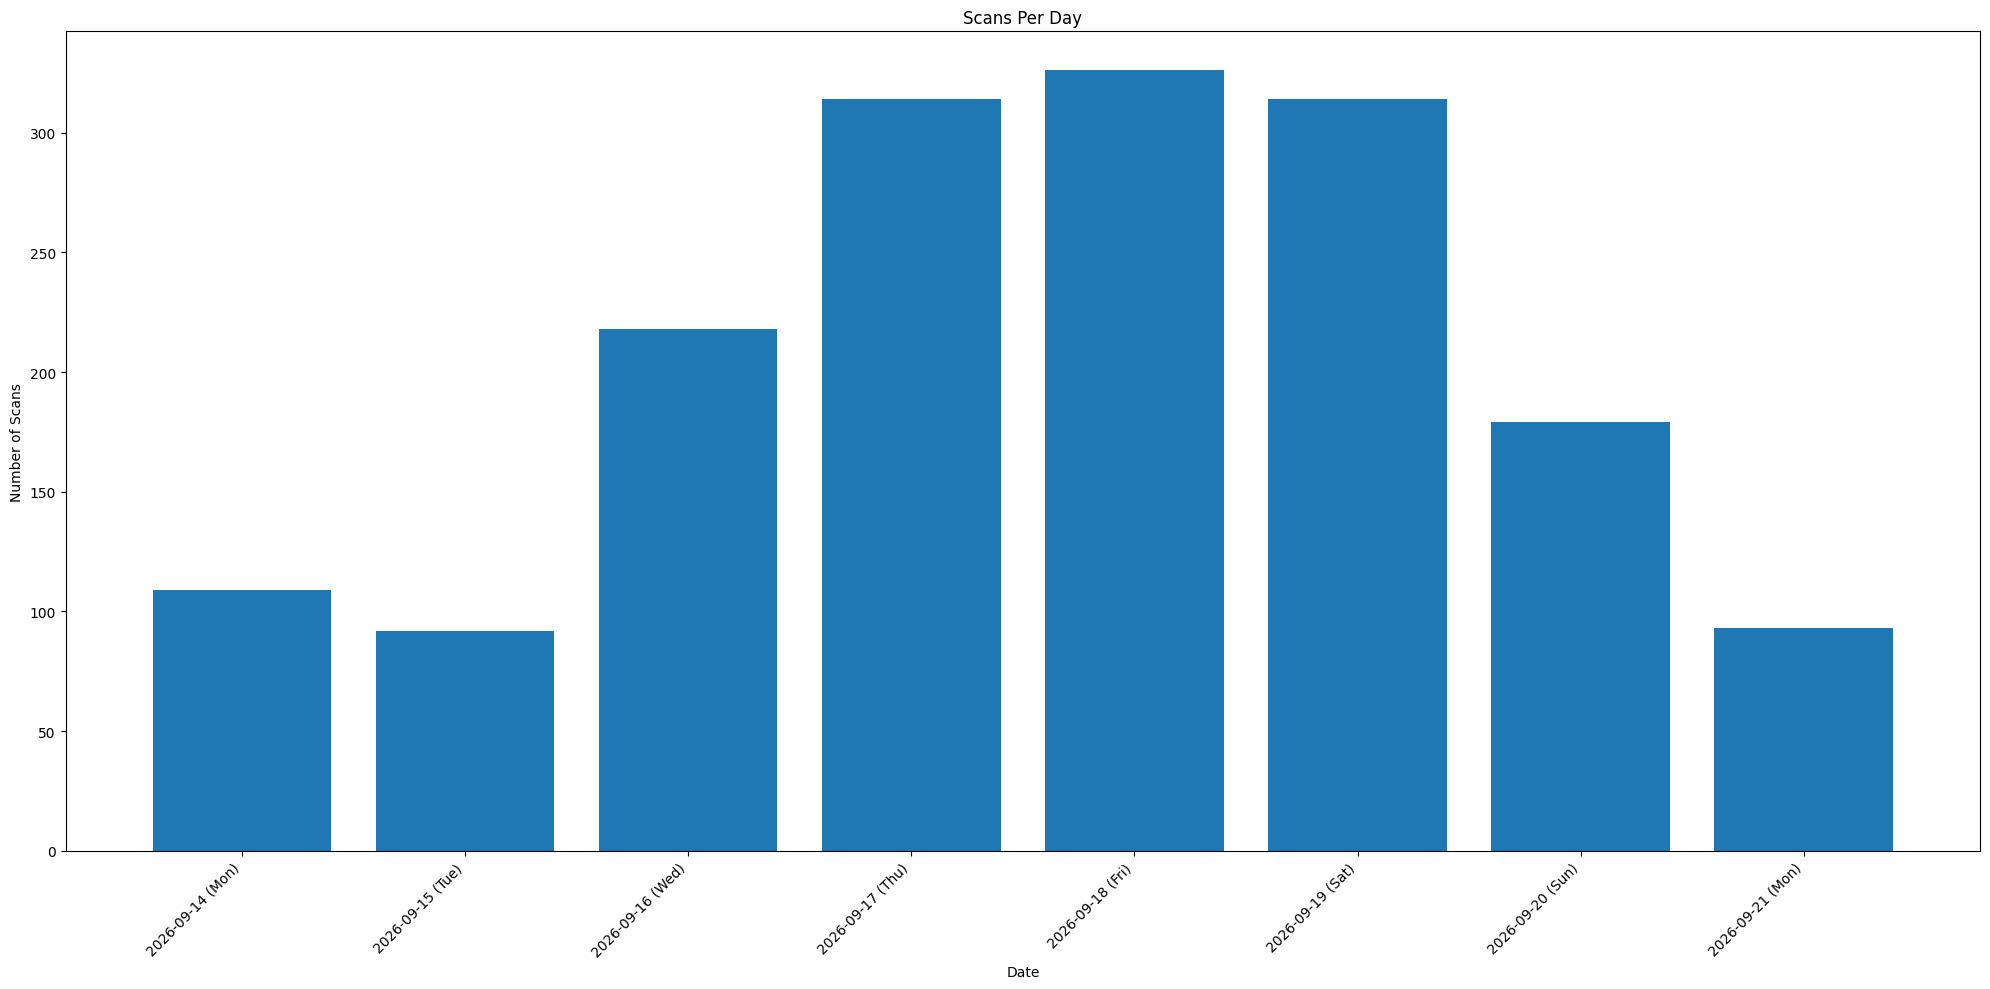

In [ ]:
# Find the total scans on each day
from pandas.core import groupby
daily_totals = df.groupby("date",as_index=False)['Scans'].sum()
daily_totals.head(20)

# Create a bar plot showing the total number of scans per day
labels = daily_totals['date'].dt.strftime('%Y-%m-%d (%a)')

# Create a bar plot showing the total number of scans per day
x = daily_totals['date']
y = daily_totals["Scans"]
fig, axes = plt.subplots(1, 1, figsize=(20, 10))
axes.bar(x, y)
axes.set_xticks(x)
axes.set_xticklabels(labels, rotation=45, ha='right')
axes.set_xlabel("Date")
axes.set_ylabel("Number of Scans")
axes.set_title("Scans Per Day")
plt.tight_layout()
plt.show()

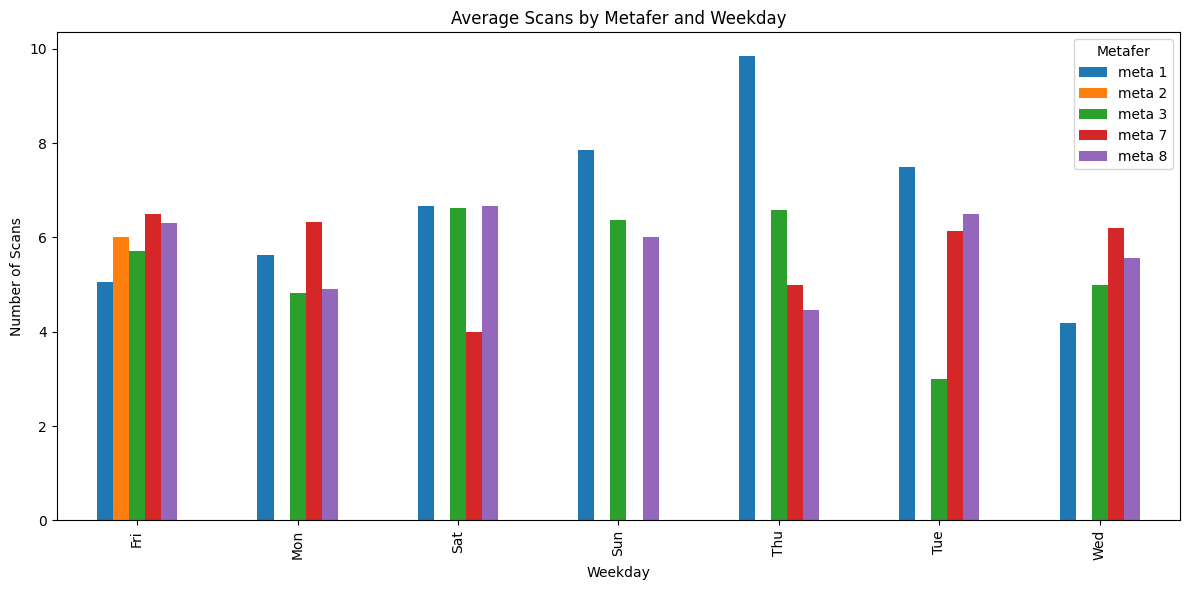

In [ ]:
# Find the total scans on each metafer by weekday
df['weekday'] = df['date'].dt.strftime('%a')

weekday_metafer_totals = (
    df.groupby(['weekday', 'Metafer'], as_index=False)['Scans']
      .mean()
)

# Create a pivot table to show the average number of scans for each metafer on each day of the week
weekday_totals_pivot = weekday_metafer_totals.pivot(
    index='weekday',
    columns='Metafer',
    values='Scans')
weekday_totals_pivot = weekday_totals_pivot.fillna(0)
weekday_totals_pivot.head()

# Create a bar plot to visualize the average number of scans for each metafer on each day of the week
weekday_totals_pivot.plot(kind='bar',figsize=(12,6))
plt.title(f"Average Scans by Metafer and Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Scans")
plt.legend(title="Metafer", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:
df.head()

,Scans,Case Type,Metafer,date,time,time_bin,weekday
0,2,BLPMF,meta 1,2026-09-18,09:57:00,09:30:00,Fri
1,6,MDSDF,meta 2,2026-09-18,00:49:00,00:30:00,Fri
2,5,PHLFD,meta 3,2026-09-17,02:18:00,02:00:00,Thu
3,4,AMLFA,meta 7,2026-09-14,07:56:00,07:30:00,Mon
4,1,BLPMF,meta 8,2026-09-14,09:47:00,09:30:00,Mon


In [ ]:
# Calculate the average number of scans for each weekday
average_daily_totals = df.groupby(["date","weekday"],as_index=False)['Scans'].sum()
average_weekday_scans = average_daily_totals.groupby("weekday",as_index=False)["Scans"].mean()

# Add the total time it would take in hours to scan the average caseload per day
average_weekday_scans["total_hours_1_metafer"] = (average_weekday_scans['Scans']*5)/60
average_weekday_scans["total_hours_2_metafers"] = ((average_weekday_scans['Scans']*5)/60)/2
average_weekday_scans["total_hours_3_metafers"] = ((average_weekday_scans['Scans']*5)/60)/3
average_weekday_scans["total_hours_4_metafers"] = ((average_weekday_scans['Scans']*5)/60)/4
average_weekday_scans["total_hours_5_metafers"] = ((average_weekday_scans['Scans']*5)/60)/5
average_weekday_scans = average_weekday_scans.round({"Scans": 2, "total_hours_1_metafer": 2, "total_hours_2_metafers": 2, "total_hours_3_metafers": 2, "total_hours_4_metafers": 2, "total_hours_5_metafers": 2})

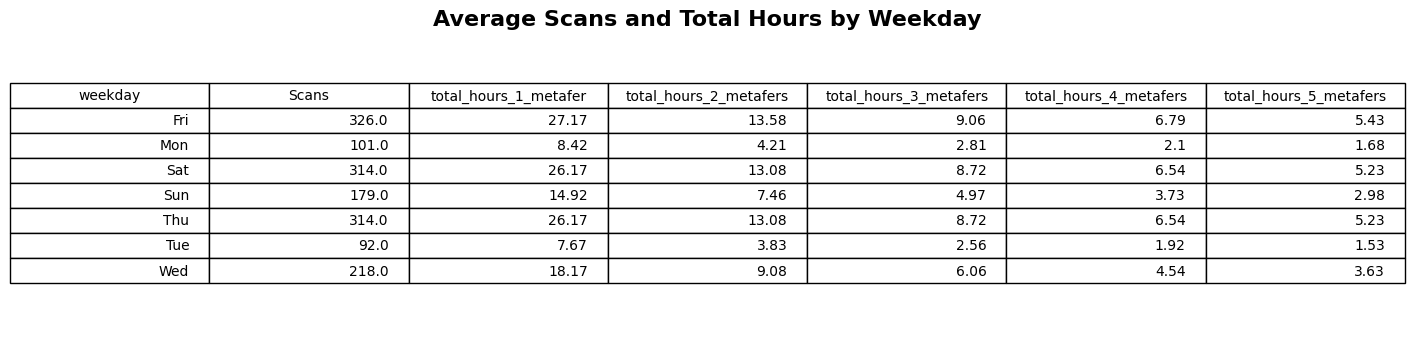

In [ ]:

# Create a table of the am average scans and total hours for each weekday
fig, ax = plt.subplots(figsize=(15, 4))
ax.axis("off")

avg_scan_table = ax.table(
    cellText=average_weekday_scans.values,
    colLabels=average_weekday_scans.columns,
    loc="center"
)

avg_scan_table.auto_set_font_size(False)
avg_scan_table.set_fontsize(10)
avg_scan_table.scale(1.2, 1.5)

plt.title(
    "Average Scans and Total Hours by Weekday",
    fontsize=16,
    weight="bold",
    pad=0
)

plt.show()

In [ ]:
# Create a dataframe for night shift and day shift
night_shift = ['00:00:00','00:30:00','01:00:00','01:30:00','02:00:00','02:30:00','03:00:00','03:30:00','15:00:00','15:30:00','16:00:00','16:30:00','17:00:00','17:30:00','18:00:00','18:30:00','19:00:00','19:30:00','20:00:00','20:30:00','21:30:00','22:00:00','22:30:00','23:00:00','23:30:00']
df['time_bin'] = df['time_bin'].astype(str)
night_shift_df = df[df["time_bin"].isin(night_shift)]

day_shift = ['04:00:00','04:30:00','05:00:00','05:30:00','06:00:00','06:30:00','07:00:00','07:30:00','08:00:00','08:30:00','09:00:00','09:30:00','10:00:00','10:30:00','11:00:00','11:30:00','12:00:00','12:30:00','13:00:00','13:30:00','14:00:00','14:30:00']
day_shift_df = df[df['time_bin'].isin(day_shift)]

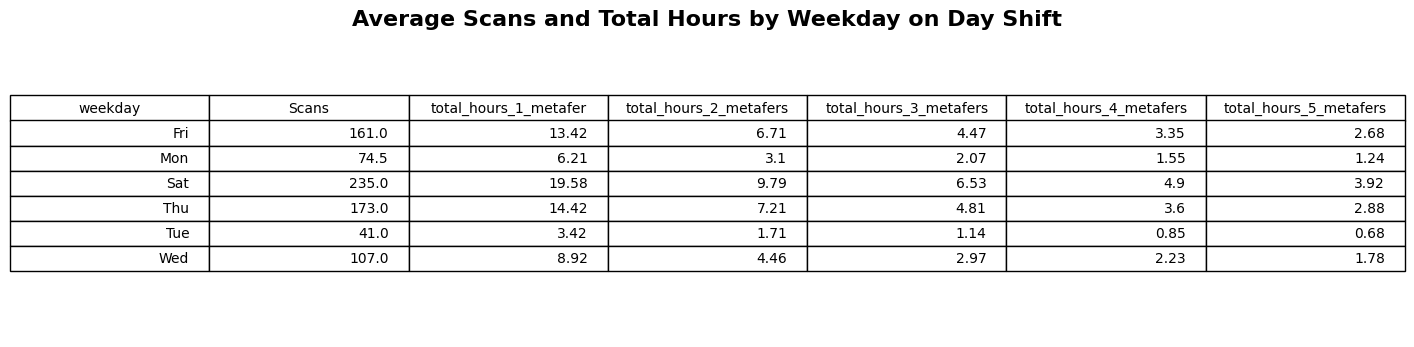

In [ ]:
# Calculate the average number of scans for each weekday day shift
average_day_shift_totals = day_shift_df.groupby(["date","weekday"],as_index=False)['Scans'].sum()
average_day_shift_weekday_scans = average_day_shift_totals.groupby("weekday",as_index=False)["Scans"].mean()

# Add the total time it would take in hours to scan the average caseload per day
average_day_shift_weekday_scans["total_hours_1_metafer"] = (average_day_shift_weekday_scans['Scans']*5)/60
average_day_shift_weekday_scans["total_hours_2_metafers"] = ((average_day_shift_weekday_scans['Scans']*5)/60)/2
average_day_shift_weekday_scans["total_hours_3_metafers"] = ((average_day_shift_weekday_scans['Scans']*5)/60)/3
average_day_shift_weekday_scans["total_hours_4_metafers"] = ((average_day_shift_weekday_scans['Scans']*5)/60)/4
average_day_shift_weekday_scans["total_hours_5_metafers"] = ((average_day_shift_weekday_scans['Scans']*5)/60)/5
average_day_shift_weekday_scans = average_day_shift_weekday_scans.round({"Scans": 2, "total_hours_1_metafer": 2, "total_hours_2_metafers": 2, "total_hours_3_metafers": 2, "total_hours_4_metafers": 2, "total_hours_5_metafers": 2})

# Create a table of the am average scans and total hours for each weekday
fig, ax = plt.subplots(figsize=(15, 4))
ax.axis("off")

avg_scan_table = ax.table(
    cellText=average_day_shift_weekday_scans.values,
    colLabels=average_day_shift_weekday_scans.columns,
    loc="center"
)

avg_scan_table.auto_set_font_size(False)
avg_scan_table.set_fontsize(10)
avg_scan_table.scale(1.2, 1.5)

plt.title(
    "Average Scans and Total Hours by Weekday on Day Shift",
    fontsize=16,
    weight="bold",
    pad=0
)

plt.show()

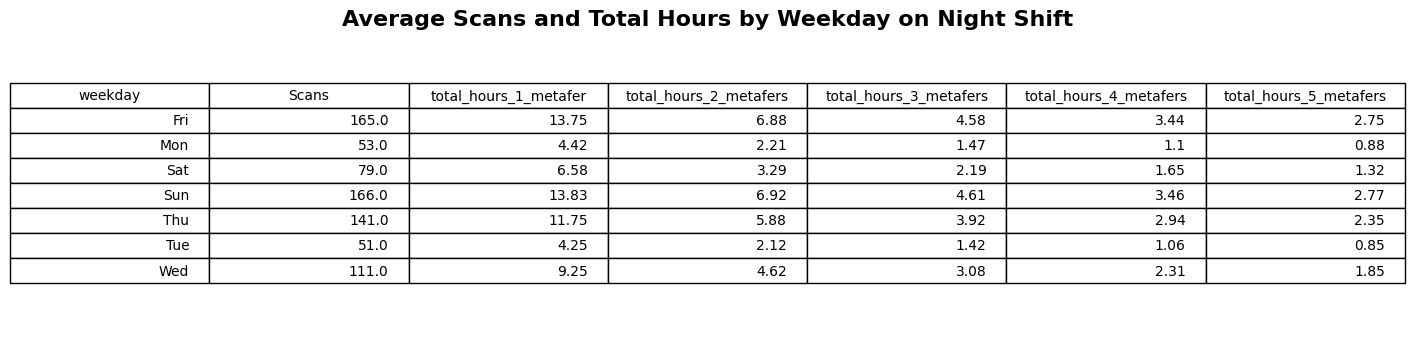

In [ ]:
# Calculate the average number of scans for each weekday day shift
average_night_shift_totals = night_shift_df.groupby(["date","weekday"],as_index=False)['Scans'].sum()
average_night_shift_weekday_scans = average_night_shift_totals.groupby("weekday",as_index=False)["Scans"].mean()

# Add the total time it would take in hours to scan the average caseload per day
average_night_shift_weekday_scans["total_hours_1_metafer"] = (average_night_shift_weekday_scans['Scans']*5)/60
average_night_shift_weekday_scans["total_hours_2_metafers"] = ((average_night_shift_weekday_scans['Scans']*5)/60)/2
average_night_shift_weekday_scans["total_hours_3_metafers"] = ((average_night_shift_weekday_scans['Scans']*5)/60)/3
average_night_shift_weekday_scans["total_hours_4_metafers"] = ((average_night_shift_weekday_scans['Scans']*5)/60)/4
average_night_shift_weekday_scans["total_hours_5_metafers"] = ((average_night_shift_weekday_scans['Scans']*5)/60)/5
average_night_shift_weekday_scans = average_night_shift_weekday_scans.round({"Scans": 2, "total_hours_1_metafer": 2, "total_hours_2_metafers": 2, "total_hours_3_metafers": 2, "total_hours_4_metafers": 2, "total_hours_5_metafers": 2})

# Create a table of the am average scans and total hours for each weekday
fig, ax = plt.subplots(figsize=(15, 4))
ax.axis("off")

avg_scan_table = ax.table(
    cellText=average_night_shift_weekday_scans.values,
    colLabels=average_night_shift_weekday_scans.columns,
    loc="center"
)

avg_scan_table.auto_set_font_size(False)
avg_scan_table.set_fontsize(10)
avg_scan_table.scale(1.2, 1.5)

plt.title(
    "Average Scans and Total Hours by Weekday on Night Shift",
    fontsize=16,
    weight="bold",
    pad=0
)

plt.show()